# 05. Frond Shape Factor

Leaf area was measured digitally via ImageJ, precise, but requiring individual image processing per frond. This notebook estimates a species-characteristic shape factor K, such that `leaf_area_cm2 ≈ K · (frond_length_cm · frond_width_cm)`, enabling future area estimates from simple linear measurements alone, without image analysis.

![ImageJ area measurement](../assets/method_screenshots/imagej_area_measurement.png)
*ImageJ workflow: the frond image is thresholded and the pixel area of the selected region is converted to cm².*

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
plt.rcdefaults()

## 2. Load Data

In [2]:
df_fronds_imputed = pd.read_csv("../data/processed/fronds_imputed.csv")
df_fronds_imputed.head()

,individual_id,frond_length_cm,frond_width_cm,n_sori_total,leaf_area_cm2,n_pinna_rows,is_imputed
0,H01,63.0,8.4,1656,280.0,86,False
1,H02,42.0,5.8,1554,130.0,59,False
2,H03,68.5,8.1,1728,266.0,80,False
3,H04,66.0,7.1,1826,216.0,89,False
4,H05,60.7,6.0,1456,194.0,82,False


## 3. Estimating the Shape Factor K

A first approach is to compute K for each individual (`K = area / (length · width)`) and average these values. However, this ratio-average method gives equal weight to every individual regardless of size, which can bias the estimate if K's relative variability differs between small and large fronds. Since the end goal is to use K as a predictive coefficient for area in real units (cm²), it is more consistent to estimate it via a no-intercept linear regression of `leaf_area_cm2` on `frond_length_cm · frond_width_cm`, this method directly finds the K value that minimizes total error in the same units later used to evaluate the formula's accuracy (the same criterion used for the average relative error). We compare both methods to check whether they produce equivalent estimates, or whether a relevant difference needs to be accounted for when reporting the final coefficient.

In [3]:
# Ratio-average method
k_per_individual = (df_fronds_imputed["leaf_area_cm2"] / (df_fronds_imputed["frond_length_cm"] * df_fronds_imputed["frond_width_cm"])).round(2)
k_ratio_avg = k_per_individual.mean()

# No-intercept regression method
LA = df_fronds_imputed["frond_length_cm"] * df_fronds_imputed["frond_width_cm"]
area = df_fronds_imputed["leaf_area_cm2"]

model_k = sm.OLS(area, LA).fit()
k_regression = model_k.params.item()

print(f"K (ratio average): {k_ratio_avg:.4f}")
print(f"K (no-intercept regression): {k_regression:.4f}")

K (ratio average): 0.5004
K (no-intercept regression): 0.4903


Both methods produce practically equivalent estimates of the shape factor: 0.5004 via ratio average and 0.4903 via no-intercept regression, a difference of barely 2%. This indicates that, for the range of frond sizes present in this sample, the potential bias of the ratio-average method discussed above has no relevant practical effect. We adopt **K = 0.50** as the species' characteristic shape factor, rounded for simplicity and consistent with both estimation methods:

**leaf_area_cm2 ≈ 0.50 · (frond_length_cm · frond_width_cm)**

## 4. Validating the Formula's Error

### 4.1 Average Error

In [4]:
df_fronds_shape = df_fronds_imputed.copy()
df_fronds_shape["area_estimated"] = 0.50 * (df_fronds_shape["frond_length_cm"] * df_fronds_shape["frond_width_cm"])
df_fronds_shape["relative_error"] = abs(df_fronds_shape["leaf_area_cm2"] - df_fronds_shape["area_estimated"]) / df_fronds_shape["leaf_area_cm2"]

print(f"Average relative error: {df_fronds_shape['relative_error'].mean():.2%}")

Average relative error: 11.36%


### 4.2 Error Distribution

In [5]:
print(f"Mean error:   {df_fronds_shape['relative_error'].mean():.2%}")
print(f"Median error: {df_fronds_shape['relative_error'].median():.2%}")
print(f"Max error:    {df_fronds_shape['relative_error'].max():.2%}")
print(f"\nIndividuals with the highest error:")
print(df_fronds_shape[["individual_id", "relative_error"]].sort_values("relative_error", ascending=False).head(5))

Mean error:   11.36%
Median error: 8.58%
Max error:    40.31%

Individuals with the highest error:
   individual_id  relative_error
9            H10        0.403077
23           H24        0.380408
12           H13        0.212665
16           H17        0.162107
18           H19        0.158209


It is worth being precise about what these errors represent. K=0.50 is not an assumption that fronds are rectangles, it is the empirical average of area / (length x width) across all 24 individuals, i.e., on average a frond fills about half of its bounding box. So a high individual error does not mean a frond "looks less like a rectangle," every frond does, that is exactly what K<1 already captures. It means that individual's own fill ratio departs from the population-average ratio of 0.50.    

Looking at the photos helps explain why some individuals diverge more than others. H10 is the clearest case: several stretches along its frond show visibly reduced or entirely absent pinnae, gaps in the leaf tissue itself, which lower its actual area relative to its bounding box more than an average frond's gaps do, a direct, visible reason for its 40.3% error. H24 shows a pronounced lanceolate taper at both base and apex, more pronounced than the degree of tapering already averaged into K. H19's rachis is noticeably bent rather than straight, which changes how well a straight length x width box captures its true footprint. H13 shows a comparable issue to H10, though more localized: toward the base and lower-middle of the frond, several pinnae pairs are visibly incomplete or missing entirely, leaving the rachis exposed on one side, an asymmetry not present in the fuller upper half of the same frond, which lowers its true area relative to its bounding box in that section. H17 tapers more sharply than most other individuals, widest around its mid-section but narrowing markedly toward both the apex and the base, combined with a slight bend in the rachis, both features shrink the leaf tissue's true footprint relative to the straight length x width box more than an average frond's taper already accounts for.

| H10 (40.3%) | H24 (38.0%) | H13 (21.3%) | H17 (16.2%) | H19 (15.8%) |
|---|---|---|---|---|
| ![H10](../assets/frond_photos/H10.jpg) | ![H24](../assets/frond_photos/H24.jpg) | ![H13](../assets/frond_photos/H13.jpg) | ![H17](../assets/frond_photos/H17.jpg) | ![H19](../assets/frond_photos/H19.jpg) |

Applying the formula `leaf_area_cm2 ≈ 0.50 · (frond_length_cm · frond_width_cm)` yields an average relative error of 11.36%, though the median (8.58%) is notably lower, confirming the mean is inflated by the handful of individuals detailed above rather than reflecting a typical case. The shape factor K=0.50 remains a reasonable and useful method for quick field area estimates, with the caveat that its precision varies between individuals, as shown above, and should not be treated as an exact measurement.


This estimate of K is based on a relatively small sample (n=24). This does not necessarily mean the value is biased, but it is more sensitive to individuals whose fill ratio departs most from the average, as discussed above, than it would be with a larger sample, where these cases would carry less relative weight on the overall average. A larger sample would allow both a more stable estimate of K and tighter confidence intervals to assess its variability. K is not used as an input in any later notebook in this pipeline, it is a standalone methodological deliverable, reported here for future field use.


### 4.3 Estimated vs. Real Area



Plotting estimated area against the real, measured area makes the error pattern visible directly: points falling near the diagonal are well-estimated, while points drifting away from it are the same high-error individuals identified numerically above.

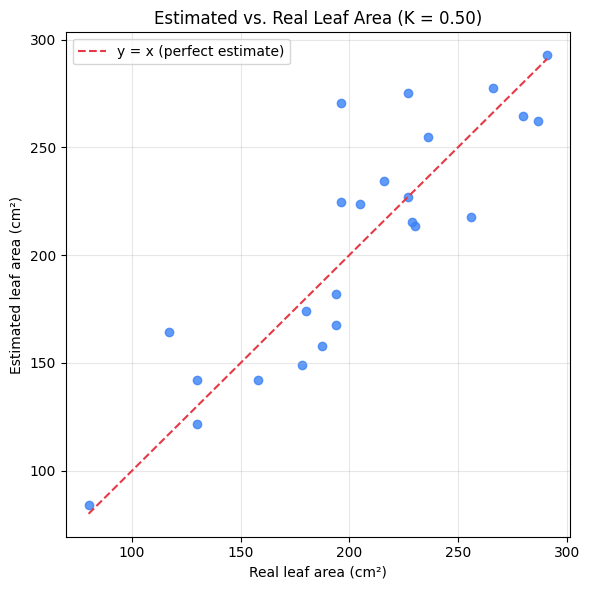

In [6]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(df_fronds_shape["leaf_area_cm2"], df_fronds_shape["area_estimated"], color="#3b82f6", alpha=0.8)

lims = [df_fronds_shape["leaf_area_cm2"].min(), df_fronds_shape["leaf_area_cm2"].max()]
ax.plot(lims, lims, "--", color="#e63946", label="y = x (perfect estimate)")

ax.set_xlabel("Real leaf area (cm²)")
ax.set_ylabel("Estimated leaf area (cm²)")
ax.set_title("Estimated vs. Real Leaf Area (K = 0.50)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../outputs/figures/05_estimated_vs_real_area.png", dpi=300, bbox_inches="tight")
plt.show()

Most individuals cluster close to the y = x line, confirming that the K = 0.50 formula estimates area reasonably well across the population. The clearest departures are the same individuals flagged above (H10, H24, H13, H17), and they consistently fall above the line rather than below it, the formula overestimates their area. This is the expected direction: K is the population-average fill ratio, so any individual whose fronds are less "full" than average, due to gaps, tapering, or a bent rachis, will have a real area smaller than K · length · width predicts, placing its point above the diagonal rather than scattered randomly around it.